# Comparing SASD definitions in the XRO forecast model

This notebook is a standalone, reproducible comparison of two definitions of the South Atlantic Subtropical Dipole (SASD) index:

- **SASD1**: the definition associated with Morioka et al. (2011)
- **SASD**: the definition associated with Ham et al. (2021)

We first compare the indices directly, then quantify how the choice of definition affects XRO reforecast skill for Nino34. The notebook is intended to be read from top to bottom and published with the generated figures and numerical summaries.

## Definitions

Both indices are differences between area-mean sea-surface-temperature anomalies (SSTAs) in a southwestern box and a northeastern box. The longitude ranges below are written in degrees west/east; the implementation uses the equivalent 0–360° longitude convention.

### SASD1 — Morioka et al. (2011)

$$\mathrm{SASD1} = \overline{\mathrm{SSTA}}_{\mathrm{SW}} - \overline{\mathrm{SSTA}}_{\mathrm{NE}}$$

where SW is the area mean over 30°W–10°W, 40°S–30°S, and NE is the area mean over 20°W–0°, 25°S–15°S.

In the code these boxes are named `SASD1_SW` and `SASD1_NE`.

### SASD — Ham et al. (2021)

$$\mathrm{SASD} = \overline{\mathrm{SSTA}}_{\mathrm{SW}} - \overline{\mathrm{SSTA}}_{\mathrm{NE}}$$

where SW is the area mean over 60°W–0°W, 45°S–35°S, and NE is the area mean over 40°W–20°E, 30°S–20°S.

In the code these boxes are named `SASD_SW` and `SASD_NE`.

## Correction and acknowledgment

This notebook documents a citation correction identified by **Dr. Tamás Bódai**, whom I thank for finding the issue. In the original Nature paper, the region description in Supplementary Table 1 was given as:

> SSTAs averaged over 60°–0°W, 45°–35°S minus those averaged over 40°W–20°E, 30°–20°S.

That region definition corresponds to the SASD index of **Ham et al. (2021)**, but it was incorrectly cited as **Morioka et al. (2011)**. The citation should therefore be corrected to Ham et al. (2021).

The two SASD definitions are very close in practice. This notebook quantifies their similarity directly and then tests whether the small definitional difference changes XRO forecast skill.

## Analysis outline

1. Load and detrend the climate indices.
2. Compare the two SASD time series and calculate their Pearson correlation.
3. Visualize the geographic boxes used by each definition.
4. Fit and reforecast the XRO model with each SASD definition.
5. Compare anomaly correlation coefficient (ACC) and mean squared error skill score (MSESS).

The climate-data loaders may require access to the configured senpy data source.

In [1]:
%config IPCompleter.greedy = True
%matplotlib inline
%config InlineBackend.figure_format='retina'

%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import senpy as sp
from senpy import calc_sst_indices, calc_wwv_indices
from senpy.models.XRO import XRO

plt.style.use('nature')

## Load and prepare the indices

The SST and warm-water-volume indices are merged onto a common monthly time axis. A second-order polynomial trend is removed over the analysis period so that the comparison focuses on variability rather than the long-term mean state.

In [ ]:
time_slice = slice('1979-01', None)
clim_slice = slice('1979-01', '2025-12')
trend_order = 1
trend_slice = slice('1979-01', '2025-12')

ssti = calc_sst_indices(model='oras5', time_slice=time_slice, clim_slice=clim_slice)
d20i = calc_wwv_indices(model='oras5', h_var='d20', time_slice=time_slice, clim_slice=clim_slice, detrend=False)
index_all_a = xr.merge([ssti, d20i])
index_all_a = index_all_a.trendPolyfit.detrend(order=trend_order, trend_period=trend_slice)
index_all_a = index_all_a.rename({'Hm': 'WWV'})

## Direct comparison of the SASD indices

The correlation is calculated over the shared time dimension. `sp.Xlinreg` provides the regression diagnostics used elsewhere in senpy; its `r` field is the Pearson correlation coefficient.

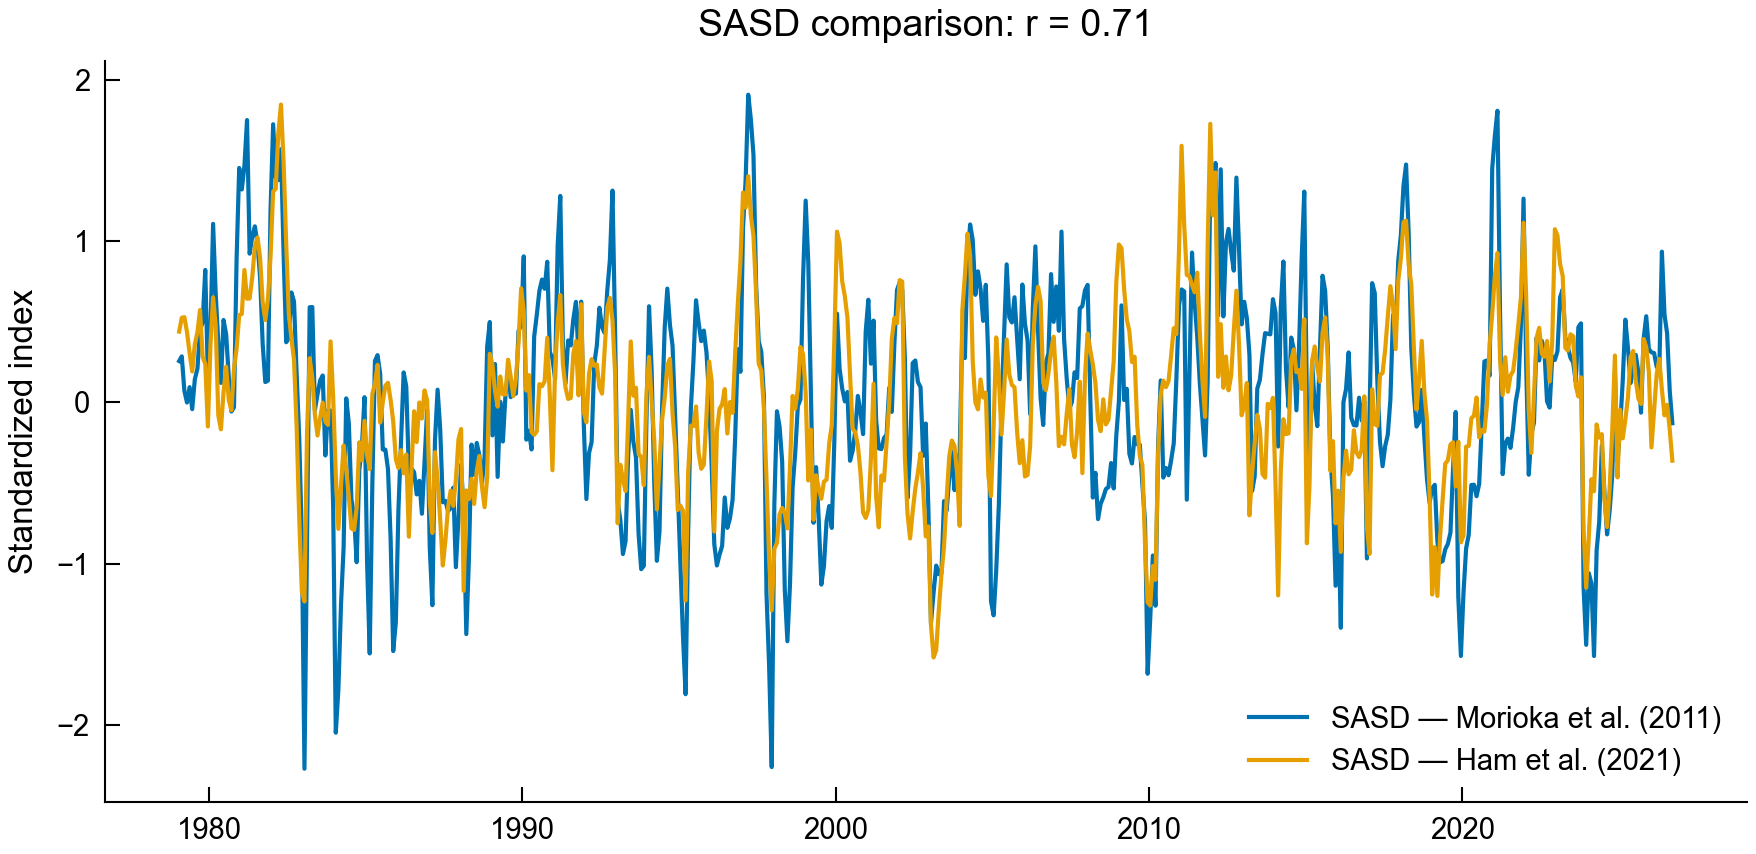

In [3]:
def compare_sasd_definitions(index_ds):
    """Plot both SASD definitions and return their Pearson correlation.

    Parameters
    ----------
    index_ds : xarray.Dataset
        Dataset containing monthly `SASD1` and `SASD` variables.

    Returns
    -------
    xarray.DataArray
        Pearson correlation coefficient between the two SASD series.
    """
    fig, ax = plt.subplots(figsize=(6, 3))
    xtime = sp.time_axis(index_ds.time)
    ax.plot(xtime, index_ds['SASD1'], label='SASD — Morioka et al. (2011)')
    ax.plot(xtime, index_ds['SASD'], label='SASD — Ham et al. (2021)')
    corr = sp.Xlinreg(index_ds['SASD1'], index_ds['SASD'], dim='time').r
    ax.set_title(f'SASD comparison: r = {corr.item():.2f}')
    ax.set_ylabel('Standardized index')
    ax.legend()
    fig.tight_layout()
    return corr

sasd_correlation = compare_sasd_definitions(index_all_a)

## Geographic definitions

The following map documents the regional boxes used to construct the two SASD indices. Red boxes denote the Morioka et al. definition; blue boxes denote the Ham et al. definition.

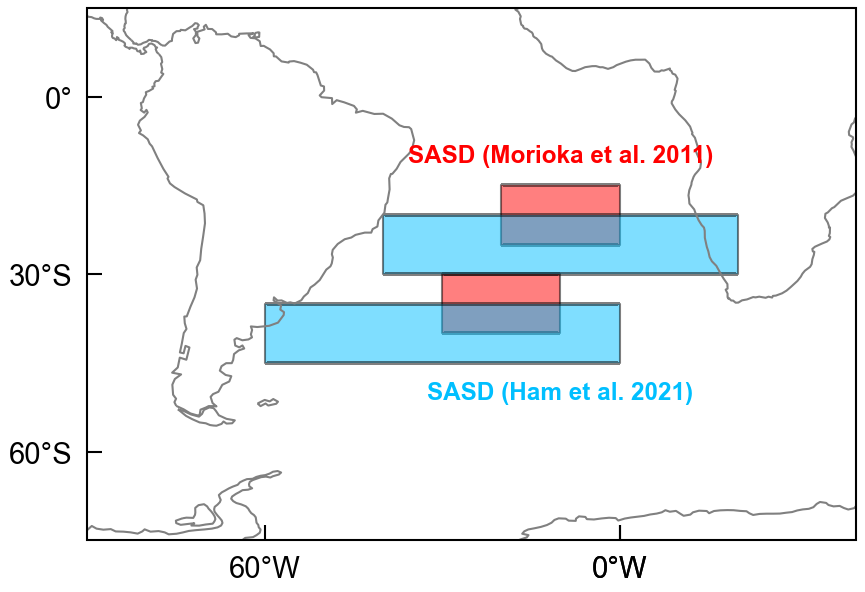

In [4]:
fig, ax = sp.map_subplots(1, 1, proj='cyl', lon_0=260, figsize=(4, 2))
sp.map_box(ax=ax, region='SASD1_NE', fc='red', ec='black', lw=0.5)
sp.map_box(ax=ax, region='SASD1_SW', fc='red', ec='black', lw=0.5)
sp.map_text(ax=ax, x=350, y=-10, s='SASD (Morioka et al. 2011)', c='red')
sp.map_box(ax=ax, region='SASD_NE', fc='deepskyblue', ec='black', lw=0.5)
sp.map_box(ax=ax, region='SASD_SW', fc='deepskyblue', ec='black', lw=0.5)
sp.map_text(ax=ax, x=350, y=-50, s='SASD (Ham et al. 2021)', c='deepskyblue')
sp.map_coastline(ax=ax)
sp.map_ticks(ax=ax, lon_lim=[270, 400], lat_lim=[-75, 15])

## XRO reforecast experiment

To isolate the effect of the SASD definition, the model configuration, fitting period, verification period, lead time, and deterministic noise treatment are held fixed. Only the SASD variable supplied to the model is changed.

In [5]:
CSfit = XRO(ncycle=12, ac_order=2, is_forward=False)

def calc_reforecast_skills(sel_vars, train_slice, 
                           verify_slice, metrics=('acc', 'msess'), 
                           by_month=False):
    """Fit XRO, generate deterministic reforecasts, and score them.

    Parameters
    ----------
    sel_vars : list[str]
        Variables included in the XRO state vector.
    train_slice, verify_slice : slice
        Time windows used for fitting and verification.
    metrics : tuple[str, ...]
        Forecast metrics passed to `sp.calc_forecast_skills`.
    by_month : bool
        Whether to retain separate scores by initialization month.

    Returns
    -------
    xarray.Dataset
        Forecast skill metrics for every selected state variable and lead.
    """
    full_ds = index_all_a[sel_vars]
    fit_train = CSfit.fitbcNRO_matrix(
        full_ds.sel(time=train_slice),
        maskb=['IOD'], maskc=[], maskNT=['T2', 'TH'], maskNH=[]
    )
    fcst_ds = CSfit.reforecast(
        fit_train, full_ds.sel(time=verify_slice), n_month=21,
        ncopy=1, seed=None, noise_type='zero'
    )
    return sp.calc_forecast_skills(
        fcst_ds, full_ds.sel(time=verify_slice), metrics=metrics,
        verify_periods=verify_slice, by_month=by_month
    )

XRO_vars_morioka = ['Nino34', 'WWV', 'NPMM', 'SPMM', 'IOB', 'IOD', 'SIOD', 'TNA', 'ATL3', 'SASD1']
XRO_vars_ham = ['Nino34', 'WWV', 'NPMM', 'SPMM', 'IOB', 'IOD', 'SIOD', 'TNA', 'ATL3', 'SASD']
verify_slice = slice('1979-01', '2025-12') # in-sample verification period
train_slice = slice('1979-01', '2025-12') # in-sample trainning period

metrics_morioka = calc_reforecast_skills(XRO_vars_morioka, train_slice, verify_slice)
metrics_ham = calc_reforecast_skills(XRO_vars_ham, train_slice, verify_slice)

## Forecast-skill comparison

ACC measures the temporal correlation between forecasts and observations. MSESS compares forecast mean-squared error with a reference forecast; larger positive values indicate greater improvement. The dashed line marks a skill value of 0.5.

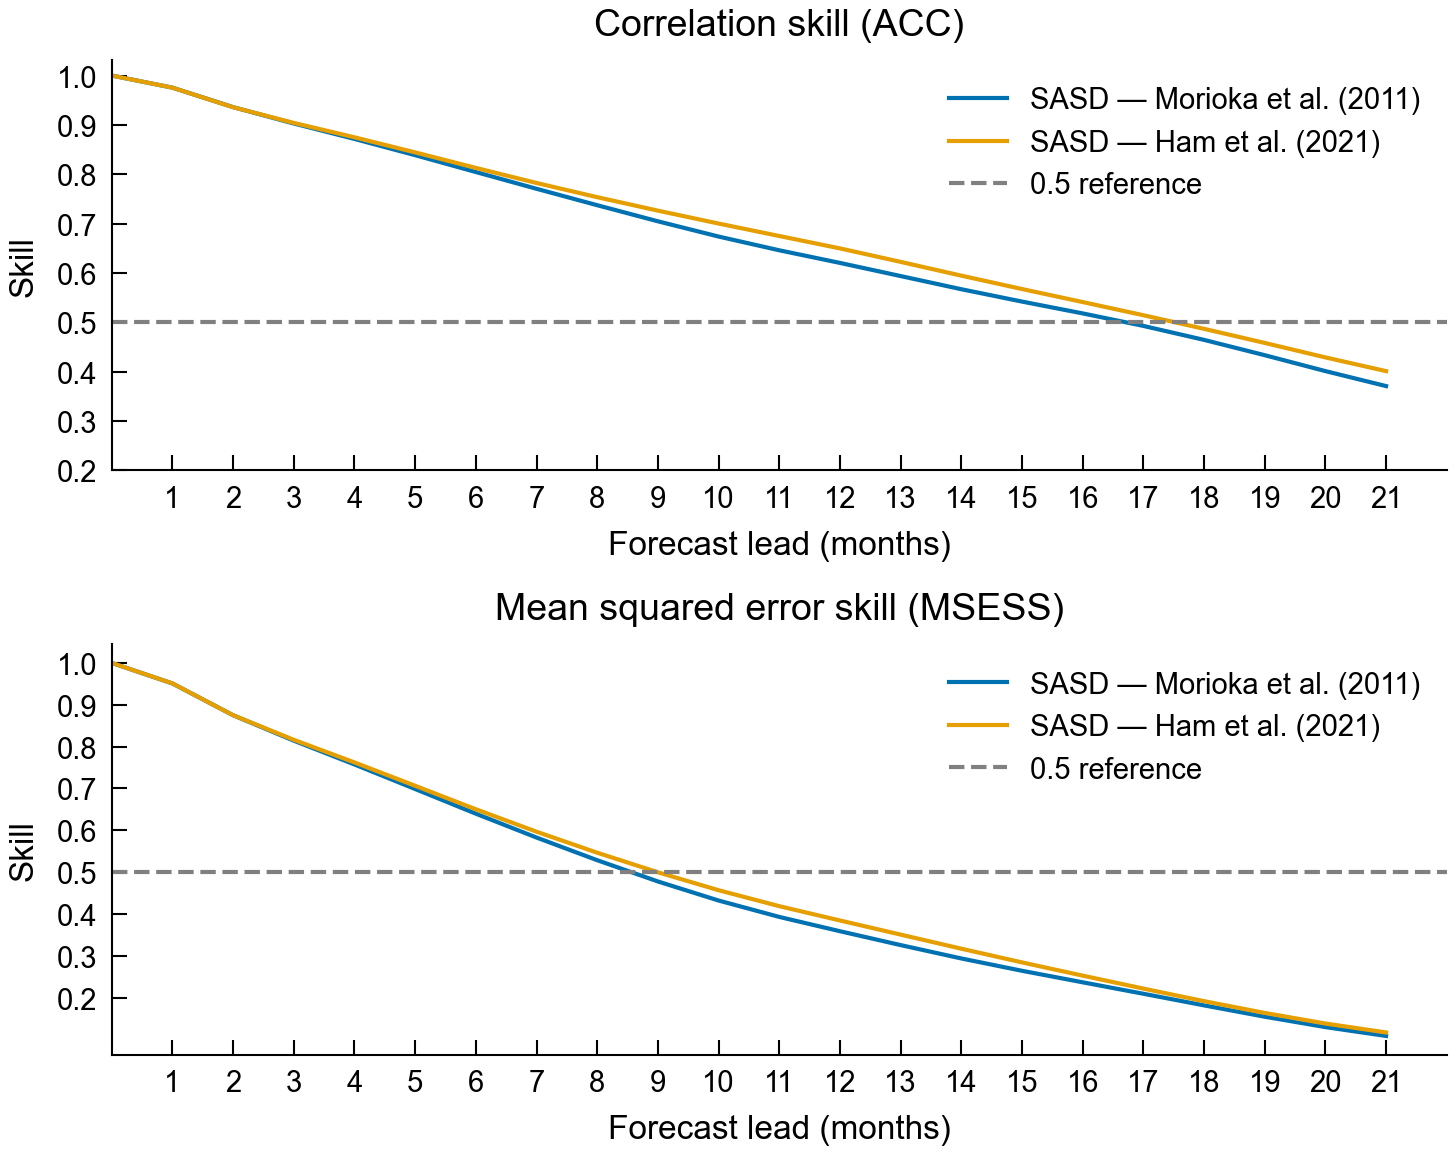

In [6]:
def plot_skill_comparison(metrics_morioka, metrics_ham, variable='Nino34'):
    """Plot ACC and MSESS for the two SASD-based XRO experiments.

    The input datasets must contain `metric`, `lead`, and `Nino34`-like
    variables produced by `sp.calc_forecast_skills`.
    """
    fig, axes = plt.subplots(2, 1, figsize=(5, 4), layout='compressed')
    labels = ('SASD — Morioka et al. (2011)', 'SASD — Ham et al. (2021)')
    for ax, metric, title in zip(axes, ('acc', 'msess'), ('Correlation skill (ACC)', 'Mean squared error skill (MSESS)')):
        metrics_morioka[variable].sel(metric=metric).plot(ax=ax, label=labels[0])
        metrics_ham[variable].sel(metric=metric).plot(ax=ax, label=labels[1])
        ax.axhline(0.5, ls='--', c='gray', label='0.5 reference')
        ax.set_title(title)
        ax.set_ylabel('Skill')
        ax.legend()
        ax.set_xticks(np.arange(1, 22, step=1))
        ax.set_yticks(np.arange(0.2, 1.01, step=0.1))
        ax.set_xlim([0, 22])
        # ax.set_ylim([0.2, 1])
        ax.set_xlabel('Forecast lead (months)')
    fig.tight_layout()
    return fig, axes

fig, axes = plot_skill_comparison(metrics_morioka, metrics_ham)
plt.show()